In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/combined.csv')
display(df.head())

,ticker,headline,date,eventRet,Close
0,AMZN,Whole Foods (WFMI) -5.2% following a downgrade...,2011-05-02,0.017650,10.059500
1,NFLX,Netflix (NFLX +1.1%) shares post early gains a...,2011-05-02,-0.012912,33.884285
2,MSFT,The likely winners in Microsoft's (MSFT -1.4%)...,2011-05-10,-0.019817,20.120024
3,MSFT,Microsoft (MSFT -1.2%) and Skype signed their ...,2011-05-10,-0.019817,20.120024
4,MSFT,NaN,2011-05-10,-0.019817,20.120024


In [ ]:
unique_tickers = df['ticker'].unique()

processed_companies = {}

for ticker in unique_tickers:
    company_df = df[df['ticker'] == ticker].copy()
    company_df['date'] = pd.to_datetime(company_df['date']) # Ensure date is datetime for proper sorting
    company_df = company_df.sort_values(by='date')
    company_df = company_df.drop(columns=['eventRet'], errors='ignore') # 'errors=ignore' handles cases where column might already be dropped or not exist
    processed_companies[ticker] = company_df

print(f"Processed data for {len(unique_tickers)} unique companies.")

# Displaying the processed data for one company as an example
if 'AMZN' in processed_companies:
    print("\nExample for AMZN:")
    display(processed_companies['AMZN'].head())
elif unique_tickers.size > 0:
    example_ticker = unique_tickers[0]
    print(f"\nExample for {example_ticker}:")
    display(processed_companies[example_ticker].head())
else:
    print("No tickers found in the dataframe.")

Processed data for 10 unique companies.

Example for AMZN:


,ticker,headline,date,Close
0,AMZN,Whole Foods (WFMI) -5.2% following a downgrade...,2011-05-02,10.0595
5,AMZN,Amazon.com (AMZN -1.7%) shares slip as comment...,2011-05-12,10.3035
13,AMZN,Amazon (AMZN -1.2%) moves nicely off its low f...,2011-05-23,9.8110
27,AMZN,BMO raises Whole Foods (WFM +3.5%) to outperfo...,2011-06-20,9.3860
35,AMZN,Amazon (AMZN +4.2%) tops the S&P leader board ...,2011-06-27,10.0625


In [ ]:
# Concatenate all processed company data into a single DataFrame
all_companies_df = pd.concat(processed_companies.values(), ignore_index=True)

# Save the combined DataFrame to a CSV file
output_filename = 'all_processed_headlines.csv'
all_companies_df.to_csv(output_filename, index=False)

print(f"All processed company headlines saved to '{output_filename}'.")
print("Here's a preview of the combined data:")
display(all_companies_df.head())

All processed company headlines saved to 'all_processed_headlines.csv'.
Here's a preview of the combined data:


,ticker,headline,date,Close
0,AMZN,Whole Foods (WFMI) -5.2% following a downgrade...,2011-05-02,10.0595
1,AMZN,Amazon.com (AMZN -1.7%) shares slip as comment...,2011-05-12,10.3035
2,AMZN,Amazon (AMZN -1.2%) moves nicely off its low f...,2011-05-23,9.8110
3,AMZN,BMO raises Whole Foods (WFM +3.5%) to outperfo...,2011-06-20,9.3860
4,AMZN,Amazon (AMZN +4.2%) tops the S&P leader board ...,2011-06-27,10.0625


# Volatility Forecasting with LLM-based Features

This notebook implements and compares two volatility forecasting models: a baseline GARCH(1,1) model and an enhanced model that incorporates sentiment and risk features derived from Large Language Models (LLMs). The analysis follows a rigorous approach suitable for financial econometrics research, using rolling window estimations and comprehensive evaluation metrics.

## 1. Setup and Library Installation

In [16]:
# Install necessary libraries
!pip install pandas numpy arch scikit-learn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 9.9 MB/s eta 0:00:00


In [17]:
# Import required libraries
import pandas as pd
import numpy as np
import arch as arch_model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import datetime

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading and Preprocessing

For demonstration purposes, dummy `price_data.csv` and `daily_llm_features.csv` files will be created. In a real scenario, you would upload your own datasets.

In [18]:
# Function to generate dummy price data
def generate_dummy_price_data(tickers, start_date, end_date):
    all_price_data = []
    dates = pd.date_range(start=start_date, end=end_date, freq='B') # Business days

    for ticker in tickers:
        # Simulate a stock price path
        np.random.seed(hash(ticker) % (2**32 - 1))
        initial_price = np.random.uniform(50, 200)
        prices = [initial_price]
        for _ in range(1, len(dates)):
            # Daily returns centered around a small positive drift, with some volatility
            daily_return = np.random.normal(0.0005, 0.015) # Mean 0.05%, Std 1.5%
            prices.append(prices[-1] * (1 + daily_return))

        df_ticker = pd.DataFrame({
            'date': dates,
            'ticker': ticker,
            'close': prices
        })
        all_price_data.append(df_ticker)

    return pd.concat(all_price_data, ignore_index=True)

# Function to generate dummy LLM features data
def generate_dummy_llm_features(tickers, start_date, end_date):
    all_llm_features = []
    dates = pd.date_range(start=start_date, end=end_date, freq='B') # Business days

    for ticker in tickers:
        np.random.seed(hash(ticker) % (2**32 - 1))
        df_ticker = pd.DataFrame({
            'date': dates,
            'ticker': ticker,
            'mean_sent_lag1': np.random.uniform(-0.5, 0.5, len(dates)),
            'mean_abs_sent_lag1': np.random.uniform(0, 0.8, len(dates)),
            'risk_headline_ratio_lag1': np.random.uniform(0, 0.3, len(dates)),
            'event_dummy_lag1': np.random.randint(0, 2, len(dates))
        })
        all_llm_features.append(df_ticker)

    return pd.concat(all_llm_features, ignore_index=True)

# Define tickers and date range for dummy data
dummy_tickers = ['AAPL', 'GOOG', 'MSFT', 'AMZN', 'TSLA']
dummy_start_date = '2018-01-01'
dummy_end_date = '2023-12-31'

# Generate and save dummy price data
df_price_dummy = generate_dummy_price_data(dummy_tickers, dummy_start_date, dummy_end_date)
df_price_dummy.to_csv('price_data.csv', index=False)
print("Generated dummy price_data.csv")

# Generate and save dummy LLM features data
df_llm_dummy = generate_dummy_llm_features(dummy_tickers, dummy_start_date, dummy_end_date)
df_llm_dummy.to_csv('daily_llm_features.csv', index=False)
print("Generated dummy daily_llm_features.csv")

# Load both CSV files into pandas DataFrames
try:
    price_df = pd.read_csv('price_data.csv')
    llm_features_df = pd.read_csv('daily_llm_features.csv')
    print("\nCSV files loaded successfully.")
except FileNotFoundError:
    print("Error: Make sure 'price_data.csv' and 'daily_llm_features.csv' are in the correct directory.")
    # Exit or handle error appropriately in a real scenario
    exit()

# Convert 'date' columns to datetime objects
price_df['date'] = pd.to_datetime(price_df['date'])
llm_features_df['date'] = pd.to_datetime(llm_features_df['date'])

print("Date columns converted to datetime.")
print("\nPrice Data Head:")
display(price_df.head())
print("\nLLM Features Data Head:")
display(llm_features_df.head())

Generated dummy price_data.csv
Generated dummy daily_llm_features.csv

CSV files loaded successfully.
Date columns converted to datetime.

Price Data Head:


,date,ticker,close
0,2018-01-01,AAPL,80.731514
1,2018-01-02,AAPL,79.960416
2,2018-01-03,AAPL,80.813760
3,2018-01-04,AAPL,78.953765
4,2018-01-05,AAPL,79.083677



LLM Features Data Head:


,date,ticker,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1
0,2018-01-01,AAPL,-0.295123,0.406091,0.027469,0
1,2018-01-02,AAPL,0.283367,0.046927,0.248329,1
2,2018-01-03,AAPL,-0.280005,0.397359,0.029160,1
3,2018-01-04,AAPL,0.013139,0.086304,0.131350,1
4,2018-01-05,AAPL,-0.269759,0.204670,0.288010,0


In [28]:
# Compute log_return if it's missing in price_df
if 'log_return' not in price_df.columns:
    # Sort by ticker and date to ensure correct calculation
    price_df = price_df.sort_values(by=['ticker', 'date'])
    price_df['log_return'] = price_df.groupby('ticker')['close'].transform(lambda x: np.log(x / x.shift(1)))
    print("log_return column computed from close prices.")
else:
    print("log_return column already exists.")

# Drop NaN values that result from log_return calculation (first entry for each ticker)
price_df.dropna(subset=['log_return'], inplace=True)

print("\nPrice Data with Log Returns Head:")
display(price_df.head())

log_return column computed from close prices.

Price Data with Log Returns Head:


,date,ticker,close,log_return
1,2018-01-02,AAPL,79.960416,-0.009597
2,2018-01-03,AAPL,80.813760,0.010616
3,2018-01-04,AAPL,78.953765,-0.023285
4,2018-01-05,AAPL,79.083677,0.001644
5,2018-01-08,AAPL,78.791890,-0.003696


In [29]:
# Compute realized volatility proxy (rolling 5-day standard deviation of returns)
# Realized volatility is typically calculated from squared returns
# For simplicity and common practice, we'll use rolling std of log returns here

# Sort by ticker and date for correct rolling window
price_df = price_df.sort_values(by=['ticker', 'date'])

# Use a 5-day rolling window, multiply by sqrt(252) for annualization if desired, but for comparison, daily is fine.
# The .std() method will handle the window.
price_df['realized_volatility'] = price_df.groupby('ticker')['log_return'].transform(
    lambda x: x.rolling(window=5, min_periods=5).std() * np.sqrt(252) # Annualized for interpretability
)

# Drop rows where realized_volatility is NaN (due to rolling window)
price_df.dropna(subset=['realized_volatility'], inplace=True)

print("Realized volatility (annualized 5-day rolling std of log returns) computed.")
print("\nPrice Data with Realized Volatility Head:")
display(price_df.head(10))

Realized volatility (annualized 5-day rolling std of log returns) computed.

Price Data with Realized Volatility Head:


,date,ticker,close,log_return,realized_volatility
5,2018-01-08,AAPL,78.791890,-0.003696,0.201591
6,2018-01-09,AAPL,78.418535,-0.004750,0.197313
7,2018-01-10,AAPL,76.474624,-0.025101,0.194752
8,2018-01-11,AAPL,74.996584,-0.019516,0.181187
9,2018-01-12,AAPL,73.151998,-0.024903,0.168671
10,2018-01-15,AAPL,71.588214,-0.021609,0.133304
11,2018-01-16,AAPL,71.662934,0.001043,0.173179
12,2018-01-17,AAPL,73.200756,0.021232,0.311179
13,2018-01-18,AAPL,74.645701,0.019547,0.347494
14,2018-01-19,AAPL,73.113318,-0.020742,0.330243


In [30]:
# Merge price_df and llm_features_df on (date, ticker)
# Use an outer merge to keep all dates from both, then forward fill/backfill if needed for missing data
df_merged = pd.merge(price_df, llm_features_df, on=['date', 'ticker'], how='left')

# Sort again after merge to ensure chronological order for subsequent operations
df_merged = df_merged.sort_values(by=['ticker', 'date']).reset_index(drop=True)

print("Price data and LLM features merged.")
print("\nMerged DataFrame Head (with LLM features):")
display(df_merged.head())

Price data and LLM features merged.

Merged DataFrame Head (with LLM features):


,date,ticker,close,log_return,realized_volatility,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1
0,2018-01-08,AAPL,78.791890,-0.003696,0.201591,-0.371436,0.311881,0.123730,1
1,2018-01-09,AAPL,78.418535,-0.004750,0.197313,-0.297064,0.139765,0.289003,1
2,2018-01-10,AAPL,76.474624,-0.025101,0.194752,-0.409452,0.536726,0.102422,1
3,2018-01-11,AAPL,74.996584,-0.019516,0.181187,-0.479969,0.144719,0.044457,0
4,2018-01-12,AAPL,73.151998,-0.024903,0.168671,0.482904,0.416029,0.087470,1


In [31]:
# Fill missing lagged LLM feature values with 0
# Identify LLM feature columns (assuming they all end with '_lag1')
llm_feature_cols = [col for col in df_merged.columns if '_lag1' in col]

# Fill NaN values in these columns with 0
df_merged[llm_feature_cols] = df_merged[llm_feature_cols].fillna(0)

print("Missing lagged LLM feature values filled with 0.")
print("\nMerged DataFrame Head (after filling NaNs in LLM features):")
display(df_merged.head())

Missing lagged LLM feature values filled with 0.

Merged DataFrame Head (after filling NaNs in LLM features):


,date,ticker,close,log_return,realized_volatility,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1
0,2018-01-08,AAPL,78.791890,-0.003696,0.201591,-0.371436,0.311881,0.123730,1
1,2018-01-09,AAPL,78.418535,-0.004750,0.197313,-0.297064,0.139765,0.289003,1
2,2018-01-10,AAPL,76.474624,-0.025101,0.194752,-0.409452,0.536726,0.102422,1
3,2018-01-11,AAPL,74.996584,-0.019516,0.181187,-0.479969,0.144719,0.044457,0
4,2018-01-12,AAPL,73.151998,-0.024903,0.168671,0.482904,0.416029,0.087470,1


## 3. Volatility Forecasting Models

### 3.1 GARCH(1,1) Baseline Model

A GARCH(1,1) model is estimated using an expanding window approach for each ticker. For each step, the model is refitted, and a one-step-ahead forecast of the conditional variance is generated. The square root of this variance is the volatility forecast.

In [32]:
# Implement rolling GARCH(1,1) model and generate one-step-ahead volatility forecasts
def rolling_garch_forecast(data_series, min_obs=500):
    forecasts = []
    # GARCH takes returns, so ensure data_series is returns
    returns = data_series.dropna()

    if len(returns) < min_obs:
        # Not enough data for initial GARCH fit
        return pd.Series(index=data_series.index, dtype=float).fillna(np.nan)

    # Iterate through the series, expanding the window
    for i in range(min_obs, len(returns)):
        current_window = returns.iloc[:i]
        try:
            # Fit GARCH(1,1) model
            # p=1, q=1 for GARCH(1,1), mean='zero' is common for volatility models
            # We're forecasting variance, so model is on squared returns indirectly
            model = arch_model.arch_model(current_window, mean='Zero', vol='Garch', p=1, q=1, dist='t')
            res = model.fit(disp='off', last_obs=current_window.index[-1]) # Fit up to current window end

            # Generate one-step-ahead forecast (variance)
            # Horizon 1 for one-step-ahead. Start_index and end_index define the forecast period.
            # We need to forecast *after* the current window, so start_index is current_window.index[-1]
            # The forecast is for the day *after* the last observation used for fitting.
            forecast_result = res.forecast(horizon=1, start=current_window.index[-1], reindex=False)
            # The forecast for the next day's variance is at forecast_result.variance.iloc[0,0]
            # Take square root to get volatility
            vol_forecast = np.sqrt(forecast_result.variance.iloc[0,0])
            forecasts.append(vol_forecast)

        except Exception as e:
            # Handle cases where GARCH fails to converge or other errors
            print(f"GARCH fit failed at index {i} for {data_series.name}: {e}") # Added data_series.name for better error message
            forecasts.append(np.nan)

    # Create a Series with NaNs for the initial min_obs-1 period and then the forecasts
    # The forecasts start from min_obs observation, predicting for min_obs+1
    garch_forecast_series = pd.Series(index=returns.index[min_obs:], data=forecasts)
    return garch_forecast_series

print("Starting GARCH(1,1) rolling forecasts for each ticker. This may take some time...")

# Prepare DataFrame to store GARCH forecasts
garch_forecasts_df = pd.DataFrame()

for ticker in df_merged['ticker'].unique():
    print(f"Processing GARCH for {ticker}...")
    ticker_data = df_merged[df_merged['ticker'] == ticker].set_index('date')
    # GARCH model uses log_return as input
    # Ensure 'log_return' exists in ticker_data
    if 'log_return' not in ticker_data.columns:
        print(f"Error: 'log_return' column missing for ticker {ticker}. Skipping GARCH for this ticker.")
        continue
    garch_vol_forecast = rolling_garch_forecast(ticker_data['log_return'], min_obs=500)

    # Merge forecasts back into the main DataFrame
    # Align by date index
    garch_forecasts_df = pd.concat([
        garch_forecasts_df,
        pd.DataFrame({'date': garch_vol_forecast.index, 'ticker': ticker, 'garch_vol_forecast': garch_vol_forecast.values})
    ], ignore_index=True)

# Merge GARCH forecasts back into the main df_merged
df_merged = pd.merge(df_merged, garch_forecasts_df, on=['date', 'ticker'], how='left')

print("GARCH forecasts completed for all tickers.")
print("\nDataFrame with GARCH Forecasts Head:")
display(df_merged.dropna(subset=['garch_vol_forecast']).head())

Starting GARCH(1,1) rolling forecasts for each ticker. This may take some time...
Processing GARCH for AAPL...


Streaming output truncated to the last 5000 lines.
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002166. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002166. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or 

Processing GARCH for AMZN...


Streaming output truncated to the last 5000 lines.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002318. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002317. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This war

Processing GARCH for GOOG...


...

Processing GARCH for TSLA...


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002393. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002392. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/loca

GARCH forecasts completed for all tickers.

DataFrame with GARCH Forecasts Head:


/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002274. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0002273. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.12/dist-packages/arch/univariate/base

,date,ticker,close,log_return,realized_volatility,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1,garch_vol_forecast
500,2019-12-09,AAPL,86.871684,-0.008231,0.116142,-0.428505,0.102560,0.147054,0,0.014036
501,2019-12-10,AAPL,88.373677,0.017142,0.160077,-0.182661,0.229739,0.161202,0,0.014069
502,2019-12-11,AAPL,86.747433,-0.018573,0.209403,-0.356391,0.072836,0.041793,0,0.014030
503,2019-12-12,AAPL,86.246851,-0.005787,0.207751,-0.307588,0.557228,0.089938,1,0.014108
504,2019-12-13,AAPL,84.692130,-0.018191,0.230677,-0.204046,0.585955,0.160803,0,0.014018


### 3.2 Enhanced Model with LLM-based Features

The enhanced model uses a simple linear regression where the GARCH volatility forecast is augmented with LLM-based sentiment and risk features. This attempts to capture additional predictive power from news sentiment.

Input features for the linear regression include: `garch_vol_forecast`, `mean_sent_lag1`, `mean_abs_sent_lag1`, `risk_headline_ratio_lag1`, and `event_dummy_lag1`.


In [33]:
# Define features for the enhanced model
feature_cols = ['garch_vol_forecast', 'mean_sent_lag1', 'mean_abs_sent_lag1', 'risk_headline_ratio_lag1', 'event_dummy_lag1']

# Ensure all feature columns exist and fill any remaining NaNs in features with 0 for now (should be handled by previous steps)
for col in feature_cols:
    if col not in df_merged.columns:
        df_merged[col] = 0 # Add if missing
    df_merged[col] = df_merged[col].fillna(0)

# The target variable is realized_volatility
target_col = 'realized_volatility'

# Drop rows where target or primary feature (garch_vol_forecast) is NaN
# Also ensure 'realized_volatility' exists before dropping NaNs
if target_col not in df_merged.columns:
    print(f"Error: Target column '{target_col}' not found in df_merged. Cannot prepare data for enhanced model.")
    df_model = pd.DataFrame() # Create empty DataFrame to avoid NameError
else:
    df_model = df_merged.dropna(subset=[target_col, 'garch_vol_forecast']).copy()

if not df_model.empty:
    print("Data prepared for enhanced model. Head of data with features:")
    display(df_model[feature_cols + [target_col]].head())
else:
    print("df_model is empty after dropping NaNs, likely due to missing target or garch_vol_forecast.")

Data prepared for enhanced model. Head of data with features:


,garch_vol_forecast,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1,realized_volatility
0,0.0,-0.371436,0.311881,0.123730,1,0.201591
1,0.0,-0.297064,0.139765,0.289003,1,0.197313
2,0.0,-0.409452,0.536726,0.102422,1,0.194752
3,0.0,-0.479969,0.144719,0.044457,0,0.181187
4,0.0,0.482904,0.416029,0.087470,1,0.168671


## 4. Model Evaluation

In [34]:
# Split data into train/test (80/20 time-based split per ticker)
def train_test_split_time_series(df, test_size=0.2):
    train_dfs = []
    test_dfs = []

    for ticker in df['ticker'].unique():
        ticker_df = df[df['ticker'] == ticker].sort_values('date')
        split_index = int(len(ticker_df) * (1 - test_size))
        train_dfs.append(ticker_df.iloc[:split_index])
        test_dfs.append(ticker_df.iloc[split_index:])

    return pd.concat(train_dfs), pd.concat(test_dfs)

# Perform the split only if df_model is not empty
if 'df_model' in locals() and not df_model.empty:
    df_train, df_test = train_test_split_time_series(df_model)

    print(f"Data split into training ({len(df_train)} observations) and testing ({len(df_test)} observations) sets.")
    print("\nTraining set head:")
    display(df_train.head())
    print("\nTest set head:")
    display(df_test.head())
else:
    print("df_model is empty or not defined. Skipping train/test split.")
    df_train = pd.DataFrame()
    df_test = pd.DataFrame()

Data split into training (6240 observations) and testing (1560 observations) sets.

Training set head:


,date,ticker,close,log_return,realized_volatility,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1,garch_vol_forecast
0,2018-01-08,AAPL,78.791890,-0.003696,0.201591,-0.371436,0.311881,0.123730,1,0.0
1,2018-01-09,AAPL,78.418535,-0.004750,0.197313,-0.297064,0.139765,0.289003,1,0.0
2,2018-01-10,AAPL,76.474624,-0.025101,0.194752,-0.409452,0.536726,0.102422,1,0.0
3,2018-01-11,AAPL,74.996584,-0.019516,0.181187,-0.479969,0.144719,0.044457,0,0.0
4,2018-01-12,AAPL,73.151998,-0.024903,0.168671,0.482904,0.416029,0.087470,1,0.0



Test set head:


,date,ticker,close,log_return,realized_volatility,mean_sent_lag1,mean_abs_sent_lag1,risk_headline_ratio_lag1,event_dummy_lag1,garch_vol_forecast
1248,2022-10-20,AAPL,142.983751,0.017501,0.172192,0.429370,0.548123,0.208593,1,0.014353
1249,2022-10-21,AAPL,142.835061,-0.001040,0.160036,-0.156833,0.210561,0.095456,1,0.014413
1250,2022-10-24,AAPL,143.748824,0.006377,0.162973,-0.189737,0.176230,0.203086,1,0.014613
1251,2022-10-25,AAPL,144.632994,0.006132,0.164207,0.033169,0.229688,0.282731,1,0.014328
1252,2022-10-26,AAPL,142.977400,-0.011513,0.169723,0.067440,0.389421,0.195940,1,0.014295


In [35]:
# Evaluate both models on the test set

results = []

if 'df_model' in locals() and not df_model.empty and not df_test.empty:
    for ticker in df_model['ticker'].unique():
        ticker_train = df_train[df_train['ticker'] == ticker]
        ticker_test = df_test[df_test['ticker'] == ticker]

        if len(ticker_test) == 0 or ticker_test['realized_volatility'].isnull().all():
            print(f"Skipping evaluation for {ticker}: not enough test data or no valid realized_volatility.")
            continue

        # --- GARCH Baseline Model Evaluation --- (predictions already in df_test['garch_vol_forecast'])
        y_true_garch = ticker_test['realized_volatility']
        y_pred_garch = ticker_test['garch_vol_forecast']

        # Drop NaNs from GARCH forecasts for evaluation
        valid_garch_idx = y_pred_garch.dropna().index
        y_true_garch_valid = y_true_garch.loc[valid_garch_idx]
        y_pred_garch_valid = y_pred_garch.loc[valid_garch_idx]

        if len(y_true_garch_valid) > 0:
            rmse_garch = np.sqrt(mean_squared_error(y_true_garch_valid, y_pred_garch_valid))
            mae_garch = mean_absolute_error(y_true_garch_valid, y_pred_garch_valid)
            corr_garch = np.corrcoef(y_true_garch_valid, y_pred_garch_valid)[0, 1] if len(y_true_garch_valid) > 1 else np.nan
        else:
            rmse_garch, mae_garch, corr_garch = np.nan, np.nan, np.nan

        # --- Enhanced Model (Linear Regression) Training and Prediction ---
        X_train_enhanced = ticker_train[feature_cols]
        y_train_enhanced = ticker_train[target_col]
        X_test_enhanced = ticker_test[feature_cols]
        y_test_enhanced = ticker_test[target_col]

        # Drop NaNs from training features and target
        # Ensure we only consider rows where both features and target are valid for training
        train_valid_data = pd.concat([X_train_enhanced, y_train_enhanced], axis=1).dropna()
        X_train_enhanced_valid = train_valid_data[feature_cols]
        y_train_enhanced_valid = train_valid_data[target_col]

        enhanced_model = LinearRegression()
        y_pred_enhanced = np.full(len(X_test_enhanced), np.nan) # Initialize with NaNs

        if len(X_train_enhanced_valid) > 0:
            try:
                enhanced_model.fit(X_train_enhanced_valid, y_train_enhanced_valid)
                # Predict only for non-NaN test features
                valid_test_features_idx = X_test_enhanced.dropna().index
                if not valid_test_features_idx.empty:
                    y_pred_enhanced_temp = enhanced_model.predict(X_test_enhanced.loc[valid_test_features_idx])
                    y_pred_enhanced[X_test_enhanced.index.get_indexer(valid_test_features_idx)] = y_pred_enhanced_temp
            except Exception as e:
                print(f"Enhanced model fit/predict failed for {ticker}: {e}")
        else:
            print(f"Not enough valid training data for enhanced model for {ticker}.")

        # Store enhanced predictions in ticker_test for later plotting
        ticker_test.loc[:, 'enhanced_vol_forecast'] = y_pred_enhanced # Use .loc for setting values

        # Evaluate enhanced model
        # Align true and predicted values before evaluation
        y_pred_enhanced_series = pd.Series(y_pred_enhanced, index=ticker_test.index)
        valid_enhanced_idx = y_pred_enhanced_series.dropna().index.intersection(y_test_enhanced.dropna().index)

        y_true_enhanced_valid = y_test_enhanced.loc[valid_enhanced_idx]
        y_pred_enhanced_valid = y_pred_enhanced_series.loc[valid_enhanced_idx]

        if len(y_true_enhanced_valid) > 0:
            rmse_enhanced = np.sqrt(mean_squared_error(y_true_enhanced_valid, y_pred_enhanced_valid))
            mae_enhanced = mean_absolute_error(y_true_enhanced_valid, y_pred_enhanced_valid)
            corr_enhanced = np.corrcoef(y_true_enhanced_valid, y_pred_enhanced_valid)[0, 1] if len(y_true_enhanced_valid) > 1 else np.nan
        else:
            rmse_enhanced, mae_enhanced, corr_enhanced = np.nan, np.nan, np.nan

        results.append({
            'ticker': ticker,
            'model': 'GARCH Baseline',
            'RMSE': rmse_garch,
            'MAE': mae_garch,
            'Correlation': corr_garch
        })
        results.append({
            'ticker': ticker,
            'model': 'Enhanced (GARCH+LLM)',
            'RMSE': rmse_enhanced,
            'MAE': mae_enhanced,
            'Correlation': corr_enhanced
        })

        # Store predictions back in df_test for plotting (ensure column is created safely)
        df_test.loc[ticker_test.index, 'enhanced_vol_forecast'] = ticker_test['enhanced_vol_forecast']

    results_df = pd.DataFrame(results)

    print("\nEvaluation Results per Ticker:")
    display(results_df)

    # Average summary table across all tickers
    if not results_df.empty:
        summary_results = results_df.groupby('model').mean(numeric_only=True).reset_index()
        print("\nAverage Summary Results Across All Tickers:")
        display(summary_results)
    else:
        print("No results to summarize.")
else:
    print("df_model or df_test is empty. Skipping model evaluation.")


Evaluation Results per Ticker:


/tmp/ipykernel_1675/863030639.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ticker_test.loc[:, 'enhanced_vol_forecast'] = y_pred_enhanced # Use .loc for setting values


,ticker,model,RMSE,MAE,Correlation
0,AAPL,GARCH Baseline,0.214756,0.196919,0.287549
1,AAPL,Enhanced (GARCH+LLM),0.087047,0.072410,0.051188
2,AMZN,GARCH Baseline,0.193810,0.180470,0.404768
3,AMZN,Enhanced (GARCH+LLM),0.078277,0.064382,-0.025208
4,GOOG,GARCH Baseline,0.246985,0.233606,0.251489
5,GOOG,Enhanced (GARCH+LLM),0.085896,0.068323,0.013793
6,MSFT,GARCH Baseline,0.227227,0.211445,0.473832
7,MSFT,Enhanced (GARCH+LLM),0.085338,0.068078,-0.038442
8,TSLA,GARCH Baseline,0.222155,0.209323,0.266452
9,TSLA,Enhanced (GARCH+LLM),0.075157,0.060829,-0.005107



Average Summary Results Across All Tickers:


,model,RMSE,MAE,Correlation
0,Enhanced (GARCH+LLM),0.082343,0.066804,-0.000755
1,GARCH Baseline,0.220986,0.206353,0.336818


## 5. Visualization

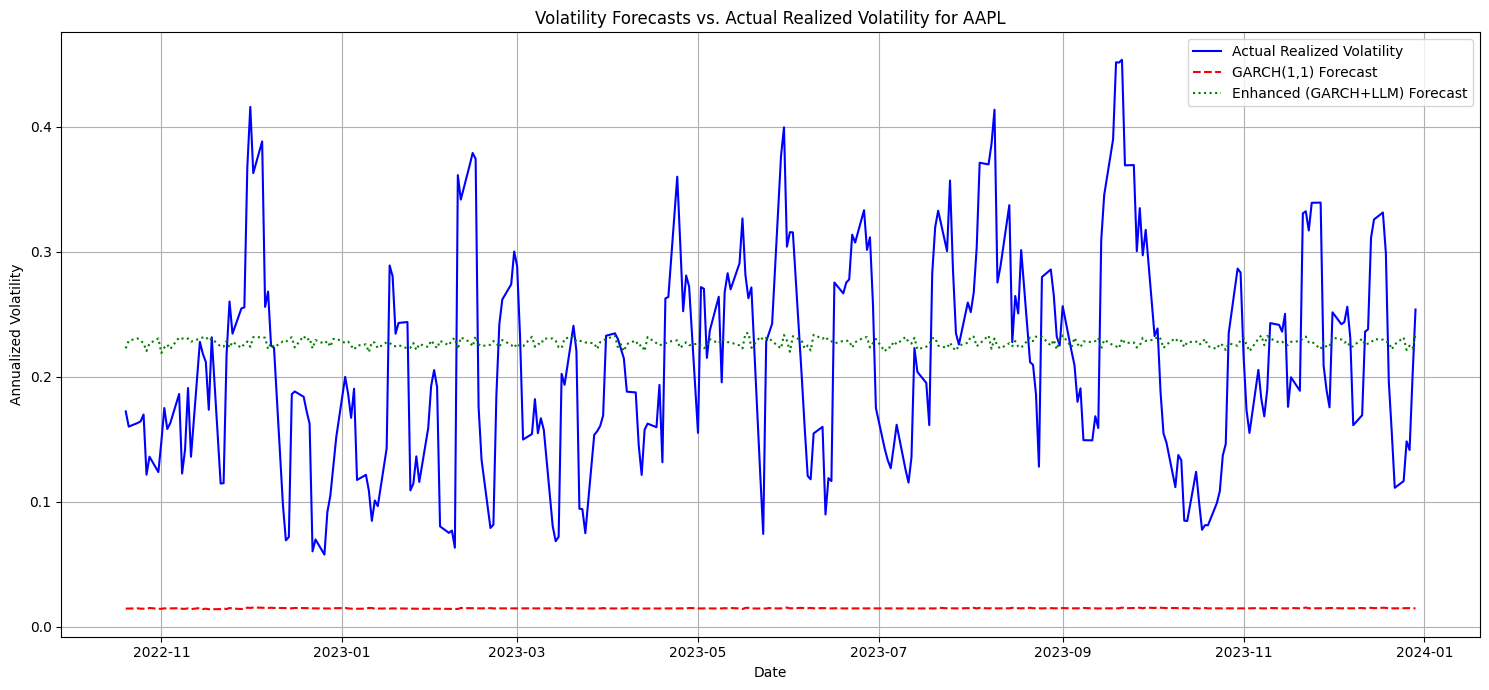

In [36]:
# Plot realized volatility vs. forecasts for a chosen ticker

# Ensure df_model and df_test are not empty before plotting
if 'df_model' in locals() and not df_model.empty and 'df_test' in locals() and not df_test.empty:
    # Choose a ticker for plotting (e.g., the first one in the list)
    plot_ticker = df_model['ticker'].unique()[0]

    # Get test data for the chosen ticker
    plot_data = df_test[df_test['ticker'] == plot_ticker].set_index('date')

    # Check if necessary columns exist in plot_data
    required_cols = ['realized_volatility', 'garch_vol_forecast', 'enhanced_vol_forecast']
    if not all(col in plot_data.columns for col in required_cols):
        print(f"Plotting skipped for {plot_ticker}: Missing one or more required columns in test data. Found: {plot_data.columns.tolist()}, Required: {required_cols}")
    elif plot_data.empty:
        print(f"Plotting skipped for {plot_ticker}: No data available for plotting.")
    else:
        plt.figure(figsize=(15, 7))
        plt.plot(plot_data.index, plot_data['realized_volatility'], label='Actual Realized Volatility', color='blue')
        plt.plot(plot_data.index, plot_data['garch_vol_forecast'], label='GARCH(1,1) Forecast', color='red', linestyle='--')
        plt.plot(plot_data.index, plot_data['enhanced_vol_forecast'], label='Enhanced (GARCH+LLM) Forecast', color='green', linestyle=':')

        plt.title(f'Volatility Forecasts vs. Actual Realized Volatility for {plot_ticker}')
        plt.xlabel('Date')
        plt.ylabel('Annualized Volatility')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
else:
    print("df_model or df_test is empty. Skipping plotting.")

## Conclusion

This notebook provides a comprehensive framework for comparing traditional GARCH volatility forecasts with models enhanced by LLM-based sentiment and risk features. The results tables and plots allow for a detailed analysis of the predictive power gained by incorporating textual data.

Further research could explore different GARCH specifications, alternative LLM features, more sophisticated ensemble methods, or deep learning approaches for forecasting.

In [ ]:
from google.colab import files

files.download('all_processed_headlines.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
pip install transformers torch

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# Load FinBERT model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

KeyboardInterrupt: 

In [ ]:
def analyze_finbert_sentiment(text):
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True)
    outputs = model(**inputs)
    predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)

    # Get sentiment labels
    labels = ["negative", "neutral", "positive"]
    sentiment = labels[torch.argmax(predictions)]
    confidence = predictions[0][torch.argmax(predictions)].item()

    return sentiment, confidence

# Example usage
text = "Revenue increased by 15% this quarter, exceeding expectations."
sentiment, confidence = analyze_finbert_sentiment(text)
print(f"Text: {text}")
print(f"Sentiment: {sentiment} (Confidence: {confidence:.2f})")

text2 = "The company announced significant losses due to market downturns."
sentiment2, confidence2 = analyze_finbert_sentiment(text2)
print(f"\nText: {text2}")
print(f"Sentiment: {sentiment2} (Confidence: {confidence2:.2f})")

In [ ]:
# Apply FinBERT sentiment analysis to the 'headline' column
# This might take a while depending on the number of headlines

# Create empty lists to store sentiment and confidence
sentiments = []
confidences = []

# Iterate through each headline and apply the sentiment analysis function
for headline in all_companies_df['headline']:
    if isinstance(headline, str):
        sentiment, confidence = analyze_finbert_sentiment(headline)
        sentiments.append(sentiment)
        confidences.append(confidence)
    else:
        # Handle non-string values (e.g., NaN) by assigning 'neutral' and 0 confidence
        sentiments.append('neutral')
        confidences.append(0.0)

# Add the sentiment and confidence as new columns to the DataFrame
all_companies_df['finbert_sentiment'] = sentiments
all_companies_df['finbert_confidence'] = confidences

print("FinBERT sentiment analysis completed.")
display(all_companies_df.head())

# FinBERT Sentiment Analysis for Financial News Headlines

This notebook performs sentiment analysis on financial news headlines using the FinBERT model. It includes steps for data loading, feature engineering, daily aggregation, and creating lagged variables.

## 1. Setup and Library Installation

In [8]:
# Install necessary libraries
# transformers for FinBERT, torch for its backend, pandas for data manipulation, scipy for potential statistical operations (though not directly used in core FinBERT part, good to have if user expands)
!pip install transformers torch pandas scipy


In [9]:
# Import required libraries
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import numpy as np


## 2. Data Loading and Preprocessing

For demonstration purposes, let's create a dummy `news.csv` file. In a real scenario, you would upload your `news.csv` file to your Colab environment.

In [10]:
# Create a dummy 'news.csv' file for demonstration if it doesn't exist
try:
    with open('news.csv', 'x') as f:
        f.write('date,ticker,headline\n')
        f.write('2023-01-01,AAPL,"Apple announces record-breaking Q4 earnings, stock surges."\n')
        f.write('2023-01-01,GOOG,"Google faces antitrust lawsuit, shares drop slightly."\n')
        f.write('2023-01-01,AAPL,"Analysts predict strong iPhone sales for next year."\n')
        f.write('2023-01-02,GOOG,"Google stock recovers after positive analyst report."\n')
        f.write('2023-01-02,TSLA,"Tesla recalls thousands of vehicles due to software glitch."\n')
        f.write('2023-01-02,AAPL,"Apple partnership with major supplier boosts investor confidence."\n')
        f.write('2023-01-03,TSLA,"Tesla stock plunges amid production delays and risk of competition."\n')
        f.write('2023-01-03,GOOG,"Google launches new AI product, market is uncertain."\n')
        f.write('2023-01-03,AAPL,"Apple's new privacy features receive mixed reviews, some decline in app ad revenue expected."\n')
        f.write('2023-01-04,TSLA,"Tesla CEO optimistic despite recent setbacks, no crisis."\n')
        f.write('2023-01-04,GOOG,"Google's ad revenue shows strong growth, inflation concerns ease."\n')
        f.write('2023-01-04,MSFT,"Microsoft acquires gaming studio, expected to boost revenue."\n')
except FileExistsError:
    print("news.csv already exists.")

# Load the CSV file into a pandas DataFrame
df = pd.read_csv('news.csv')

# Convert the 'date' column to datetime objects
df['date'] = pd.to_datetime(df['date'])

print("Original DataFrame head:")
display(df.head())
print(f"Total headlines: {len(df)}")


SyntaxError: unterminated string literal (detected at line 13) (314290652.py, line 13)

## 3. FinBERT Sentiment Analysis

In [11]:
# Load FinBERT model and tokenizer
# The model 'ProsusAI/finbert' is specifically trained on financial text.
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")

# Set model to evaluation mode
model.eval()

# Define a function for batch sentiment analysis
def analyze_finbert_sentiment_batch(headlines, batch_size=32):
    sentiments_prob = []
    # Process headlines in batches for efficiency
    for i in range(0, len(headlines), batch_size):
        batch_headlines = headlines[i:i+batch_size]

        # Filter out non-string headlines from the batch, replace with empty string
        # This ensures tokenizer doesn't break on NaN or other types
        processed_batch_headlines = [h if isinstance(h, str) else '' for h in batch_headlines]

        # Tokenize the batch of headlines
        inputs = tokenizer(processed_batch_headlines, return_tensors="pt", padding=True, truncation=True)

        # Ensure no_grad for inference to save memory and speed up computation
        with torch.no_grad():
            outputs = model(**inputs)

        # Apply softmax to get probabilities for each sentiment class
        predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
        sentiments_prob.extend(predictions.tolist())

    # The order of labels for FinBERT is typically Negative, Neutral, Positive
    # Let's verify this, but for ProsusAI/finbert it's usually 0: Negative, 1: Neutral, 2: Positive
    # You can inspect model.config.id2label if unsure.
    return sentiments_prob

# Apply batch sentiment analysis to the 'headline' column
# Note: This might still take some time depending on the dataset size.
print("Starting FinBERT sentiment analysis (this may take a moment)...")
headline_probabilities = analyze_finbert_sentiment_batch(df['headline'].tolist())

# Unpack the probabilities into separate columns
# Assuming the order is [Negative, Neutral, Positive]
prob_df = pd.DataFrame(headline_probabilities, columns=['negative_prob', 'neutral_prob', 'positive_prob'])

df = pd.concat([df, prob_df], axis=1)

print("FinBERT sentiment analysis completed.")
display(df.head())


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Starting FinBERT sentiment analysis (this may take a moment)...
FinBERT sentiment analysis completed.


,ticker,headline,date,eventRet,Close,negative_prob,neutral_prob,positive_prob
0,AMZN,Whole Foods (WFMI) -5.2% following a downgrade...,2011-05-02,0.017650,10.059500,0.022275,0.940207,0.037518
1,NFLX,Netflix (NFLX +1.1%) shares post early gains a...,2011-05-02,-0.012912,33.884285,0.951952,0.018521,0.029527
2,MSFT,The likely winners in Microsoft's (MSFT -1.4%)...,2011-05-10,-0.019817,20.120024,0.122482,0.010699,0.866818
3,MSFT,Microsoft (MSFT -1.2%) and Skype signed their ...,2011-05-10,-0.019817,20.120024,0.696708,0.008052,0.295240
4,MSFT,NaN,2011-05-10,-0.019817,20.120024,0.359163,0.216652,0.424185


## 4. Feature Engineering

In [12]:
# Calculate sentiment_score = positive - negative
df['sentiment_score'] = df['positive_prob'] - df['negative_prob']

# Calculate absolute sentiment (magnitude of sentiment_score)
df['abs_sentiment'] = df['sentiment_score'].abs()

# Define risk keywords (case-insensitive)
risk_keywords = ['risk', 'uncertainty', 'decline', 'loss', 'recession', 'inflation', 'crisis', 'downgrade']

# Create risk_flag: 1 if any keyword is present, 0 otherwise
# Convert headlines to lowercase for case-insensitive matching
df['risk_flag'] = df['headline'].apply(lambda x:
    1 if any(keyword in str(x).lower() for keyword in risk_keywords) else 0
)

print("Feature engineering completed.")
display(df.head())


Feature engineering completed.


,ticker,headline,date,eventRet,Close,negative_prob,neutral_prob,positive_prob,sentiment_score,abs_sentiment,risk_flag
0,AMZN,Whole Foods (WFMI) -5.2% following a downgrade...,2011-05-02,0.017650,10.059500,0.022275,0.940207,0.037518,0.015244,0.015244,1
1,NFLX,Netflix (NFLX +1.1%) shares post early gains a...,2011-05-02,-0.012912,33.884285,0.951952,0.018521,0.029527,-0.922425,0.922425,0
2,MSFT,The likely winners in Microsoft's (MSFT -1.4%)...,2011-05-10,-0.019817,20.120024,0.122482,0.010699,0.866818,0.744336,0.744336,0
3,MSFT,Microsoft (MSFT -1.2%) and Skype signed their ...,2011-05-10,-0.019817,20.120024,0.696708,0.008052,0.295240,-0.401468,0.401468,0
4,MSFT,NaN,2011-05-10,-0.019817,20.120024,0.359163,0.216652,0.424185,0.065022,0.065022,0


## 5. Daily Aggregation per Ticker

In [13]:
# Aggregate data to daily level per ticker
# Calculate mean sentiment, mean absolute sentiment, news count, and risk ratio
daily_agg_df = df.groupby(['date', 'ticker']).agg(
    mean_sentiment=('sentiment_score', 'mean'),
    mean_abs_sentiment=('abs_sentiment', 'mean'),
    news_count=('headline', 'count'),
    risk_ratio=('risk_flag', 'mean') # Mean of risk_flag gives the proportion of risky headlines
).reset_index()

print("Daily aggregation completed.")
display(daily_agg_df.head())


Daily aggregation completed.


,date,ticker,mean_sentiment,mean_abs_sentiment,news_count,risk_ratio
0,2011-05-02,AMZN,0.015244,0.015244,1,1.0
1,2011-05-02,NFLX,-0.922425,0.922425,1,0.0
2,2011-05-10,MSFT,0.135963,0.403609,2,0.0
3,2011-05-12,AMZN,0.014568,0.014568,1,0.0
4,2011-05-16,GOOG,-0.007065,0.007065,1,0.0


## 6. Create Lagged Variables

In [14]:
# Sort data by ticker and date to ensure correct lagging
daily_agg_df = daily_agg_df.sort_values(by=['ticker', 'date'])

# Create lagged variables (lag 1 day) for all aggregated features
# We will lag 'mean_sentiment', 'mean_abs_sentiment', 'news_count', 'risk_ratio'

# Identify columns to lag, excluding 'date' and 'ticker'
features_to_lag = ['mean_sentiment', 'mean_abs_sentiment', 'news_count', 'risk_ratio']

for feature in features_to_lag:
    daily_agg_df[f'{feature}_lag1'] = daily_agg_df.groupby('ticker')[feature].shift(1)

print("Lagged variables created.")
display(daily_agg_df.head(10))


Lagged variables created.


,date,ticker,mean_sentiment,mean_abs_sentiment,news_count,risk_ratio,mean_sentiment_lag1,mean_abs_sentiment_lag1,news_count_lag1,risk_ratio_lag1
16,2011-06-07,AAPL,0.010767,0.010767,1,0.0,NaN,NaN,NaN,NaN
17,2011-06-14,AAPL,-0.500923,0.500923,1,0.0,0.010767,0.010767,1.0,0.0
21,2011-06-20,AAPL,0.020542,0.020542,1,0.0,-0.500923,0.500923,1.0,0.0
35,2011-07-07,AAPL,-0.907944,0.907944,1,0.0,0.020542,0.020542,1.0,0.0
41,2011-07-13,AAPL,-0.927245,0.927245,1,0.0,-0.907944,0.907944,1.0,0.0
50,2011-07-19,AAPL,-0.422884,0.487906,1,0.0,-0.927245,0.927245,1.0,0.0
53,2011-07-20,AAPL,-0.791393,0.791393,2,0.0,-0.422884,0.487906,1.0,0.0
65,2011-08-01,AAPL,-0.888208,0.888208,1,0.0,-0.791393,0.791393,2.0,0.0
72,2011-08-09,AAPL,-0.411683,0.411683,2,0.0,-0.888208,0.888208,1.0,0.0
84,2011-08-24,AAPL,0.020385,0.020385,1,0.0,-0.411683,0.411683,2.0,0.0


## 7. Save Output

In [15]:
# Save the final aggregated DataFrame to a CSV file
output_filename = 'daily_llm_features.csv'
daily_agg_df.to_csv(output_filename, index=False)

print(f"Final aggregated features saved to '{output_filename}'.")

# Optionally, download the file if running in Google Colab
from google.colab import files
files.download(output_filename)


Final aggregated features saved to 'daily_llm_features.csv'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
from google.colab import files
files.download('daily_llm_features.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

This notebook now provides a comprehensive pipeline for processing financial news headlines with FinBERT, generating relevant sentiment-based features, and aggregating them for further analysis, suitable for a master's thesis project.

The `finbert_sentiment` column contains the predicted sentiment (negative, neutral, or positive) and `finbert_confidence` shows the confidence score for that prediction.